# 🎭 Rəqabətli Generativ Şəbəkələr (Generative Adversarial Networks - GAN)

## 🧥 FashionMNIST üzərində Süni İntellektlə Yeni Geyim Dizaynlarının Yaradılması

Bu notebookda Dərin Öyrənmənin ən məşhur və inqilabi sahələrindən biri olan **GAN (Generative Adversarial Networks)** arxitekturasını sıfırdan quracaq, öyrədəcək və tamamilə yeni süni geyim kolleksiyası hasil edəcəyik!

---

### 💡 GAN Nədir? (Ian Goodfellow, 2014)
2014-cü ildə Ian Goodfellow və həmkarları tərəfindən irəli sürülmüş GAN arxitekturası iki neyron şəbəkəsinin bir-biri ilə **rəqabət apardığı (Adversarial Minimax Game)** bir sistemdir:

* 🎨 **1. Generator (Saxtakar / Rəssam):**
  * Təsadüfi riyazi səs-küydən (*Random Gaussian Noise*) başlayaraq elə inandırıcı saxta şəkillər çəkməyə çalışır ki, heç kim onun saxta olduğunu anlamasın.
* 🕵️ **2. Discriminator (Detektiv / Polis / Tənqidçi):**
  * Qarşısına qoyulan şəklin **həqiqi bazadan (*Real*)**, yoxsa **Generatorun çəkdiyi saxta (*Fake*)** olduğunu ayırd etməyə çalışan binar təsnifatçıdır (*Binary Classifier*).

### ⚖️ Oyun Nəzəriyyəsi və Neş Tarazlığı (Nash Equilibrium):
Hər iki şəbəkə bir-birini təkmilləşdirir:
* Əvvəlcə Generator bərbad şəkillər çəkir, Diskriminator onları dərhal tutur.
* Diskriminatordan dərs çıxaran Generator getdikcə daha peşəkar saxtakara çevrilir.
* Sonda **Neş Tarazlığı (*Nash Equilibrium*)** yaranır: Generator o qədər mükəmməl şəkillər çəkir ki, hətta ən peşəkar Diskriminator belə çaş-baş qalır və düzgün cavab ehtimalı $50\%$-ə enir (yəni yazı-pozu atmaq kimi təsadüfi qərar verir: $D(G(z)) = 0.5$)!

---

### ⚡ GPU Tələbi:
Qenerativ rəqabətli modellərin təlimi çoxlu matris və konvolyusiya hesablamaları tələb etdiyi üçün mütləq GPU-dan istifadə tövsiyə olunur.

In [10]:
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras import layers

import numpy as np
from matplotlib import pyplot as plt


# Təkrarlana bilən nəticələr üçün təsadüfilik toxumunu (Seed) sabitləyirik
tf.random.set_seed(1)

# Sistemdə aktiv GPU cihazlarının sayını yoxlayırıq (Confirm GPU is available)
gpus = tf.config.list_physical_devices('GPU')
print("Mövcud GPU-ların Sayı (Num GPUs Available):", len(gpus))
if gpus:
    print("Aktiv GPU:", gpus[0].name)
else:
    print("Məlumat: GPU tapılmadı, təlim CPU üzərində aparılacaq.")

Mövcud GPU-ların Sayı (Num GPUs Available): 0
Məlumat: GPU tapılmadı, təlim CPU üzərində aparılacaq.


## 👗 FashionMNIST Verilənlər Dəstinin Yüklənməsi və Birləşdirilməsi

VAE modelində olduğu kimi, **GAN-lar da təsnifat modeli deyil, paylanma öyrənən Qenerativ modellərdir**. 

Bizə modelin hansısa test dəstində faizlə dəqiqliyini ölçmək lazım deyil; əsas məqsəd Qeneratorun real geyim şəkillərinin ümumi ehtimal paylanmasını mənimsəməsidir. Buna görə də daha zəngin və böyük təlim bazası əldə etmək üçün 60,000 təlim və 10,000 test şəklini birləşdirərək **70,000 şəkildən ibarət vahid massiv** yaradırıq.

In [2]:
(x_train, y_train), (x_test, y_test) = fashion_mnist.load_data()

print(x_train.shape)
print(x_test.shape) 
print(y_train.shape)
print(y_test.shape) 

(60000, 28, 28)
(10000, 28, 28)
(60000,)
(10000,)


In [3]:
# Train və Test massivlərini vahid datasetdə birləşdiririk (70,000 şəkil)
dataset = np.concatenate([x_train, x_test], axis=0)

# Pikselləri [0, 255] aralığından [0, 1] aralığına normallaşdırırıq
# və sonuna kanal ölçüsü əlavə edirik: (28, 28) -> (28, 28, 1)
dataset = np.expand_dims(dataset, -1).astype("float32") / 255.0
print("Birləşdirilmiş və normallaşdırılmış dataset forması:", dataset.shape)

Birləşdirilmiş və normallaşdırılmış dataset forması: (70000, 28, 28, 1)


## 🔄 `tf.data.Dataset` ilə Yüksək Məhsuldarlıqlı Məlumat Boru Xətti (Data Pipeline)

Neyron şəbəkəsinin GPU-da fasiləsiz və yüksək sürətlə qidalanması üçün TensorFlow-un `tf.data.Dataset` API-sindən istifadə edirik:
* **Yenidən Formalaşdırma (*Reshape*):** `(-1, 28, 28, 1)` formasına salınır.
* **Qarışdırma (*Shuffle*):** `buffer_size=1024` ilə hər epoxda şəkillər qarışdırılır ki, model nümunələrin sırasını əzbərləməsin.
* **Partiyalaşdırma (*Batching*):** `BATCH_SIZE = 64` seçilir (hər addımda 64 şəkil emal olunur).

In [4]:
BATCH_SIZE = 64

# Şəkilləri 4D tenzor formasına gətiririk: (Nümunə sayı, 28, 28, 1)
dataset = np.reshape(dataset, (-1, 28, 28, 1))

# TensorFlow Dataset obyektini yaradırıq
dataset = tf.data.Dataset.from_tensor_slices(dataset)

# Məlumatı qarışdırırıq və 64-lük partiyalara (batch) bölürük
dataset = dataset.shuffle(buffer_size=1024).batch(BATCH_SIZE)
print("TensorFlow Dataset uğurla konfiqurasiya edildi.")

TensorFlow Dataset uğurla konfiqurasiya edildi.


## 🎨 Generator Arxitekturası: Səs-küydən Şəkilə

Generator təsadüfi Gauss səs-küyündən ibarət **64-ölçülü gizli vektor ($z \in \mathbb{R}^{64}$, `NOISE_DIM = 64`)** qəbul edir və onu addım-addım $28 \times 28 \times 1$ ölçülü realistik geyim şəklinə çevirir.

### 🔍 Əsas Laylar və İş Prinsipləri:
1. **`Dense(7 * 7 * 256)` və `Reshape((7, 7, 256))`:**  
   64 rəqəmlik səs-küyü genişləndirərək $7 \times 7$ ölçülü və 256 kanallı kiçik xüsusiyyət xəritəsinə çevirir.
2. **`Conv2DTranspose` (Tərs/Genişləndirici Konvolyusiya):**  
   Xüsusiyyət xəritəsini addım-addım böyüdür:
   * 1-ci Transpose: $7 \times 7 \to 14 \times 14$ (256 filtr)
   * 2-ci Transpose: $14 \times 14 \to 28 \times 28$ (128 filtr)
   * 3-cü Transpose: $28 \times 28 \to 28 \times 28$ (1 kanal, `sigmoid` aktivasiyası)
3. **`LeakyReLU` Aktivasiyası:**  
   Klassik ReLU mənfi dəyərləri tam sıfırlayaraq bəzi neyronları "öldürürdü" (*Dying ReLU*). `LeakyReLU` isə mənfi tərəfdə kiçik bir maillik saxlayaraq ($0.2$) qradiyent axınını canlı saxlayır və GAN təlimini sabitləşdirir.

In [5]:
NOISE_DIM = 64  # Giriş səs-küy vektorunun ölçüsü (Latent Dimension)

# Generator Modeli: Səs-küy (64) -> Şəkil (28x28x1)
generator = keras.models.Sequential([
    keras.layers.InputLayer(input_shape=(NOISE_DIM,)),
    # 1. Giriş vektorunu 7x7x256 həcminə proyeksiya edirik
    layers.Dense(7 * 7 * 256),
    layers.Reshape(target_shape=(7, 7, 256)),
    
    # 2. Genişləndirici Konvolyusiya: 7x7 -> 14x14
    layers.Conv2DTranspose(256, 3, activation="leaky_relu", strides=2, padding="same"),
    
    # 3. Genişləndirici Konvolyusiya: 14x14 -> 28x28
    layers.Conv2DTranspose(128, 3, activation="leaky_relu", strides=2, padding="same"),
    
    # 4. Yekun Çıxış Layı: 28x28x1, piksellər [0, 1] aralığında
    layers.Conv2DTranspose(1, 3, activation="sigmoid", padding="same")
], name="Generator")

generator.summary()

c:\Users\tarlan.cabiyev\AppData\Local\anaconda3\envs\tf_env\Lib\site-packages\keras\src\layers\core\input_layer.py:27: UserWarning: Argument `input_shape` is deprecated. Use `shape` instead.
  warnings.warn(


Model: "Generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 12544)          │       815,360 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 14, 14, 256)    │       590,080 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 28, 28, 128)    │       295,040 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 28, 28, 1)      │         1,153 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,701,633 (6.49 MB)

 Trainable params: 1,701,633 (6.49 MB)

 Non-trainable params: 0 (0.00 B)

## 🕵️ Discriminator (Diskriminator) Arxitekturası: Detektivin Gözü

Diskriminatorun vəzifəsi daxil olan $28 \times 28 \times 1$ ölçülü şəkli analiz edərək onun **Həqiqi ($1.0$)**, yoxsa **Saxta ($0.0$)** olduğunu müəyyənləşdirməkdir.

### 🔍 Arxitektura Xüsusiyyətləri:
* **`Conv2D` Layları:** Şəkli addım-addım süzərək ölçünü kiçildir ($28 \times 28 \to 14 \times 14 \to 7 \times 7$) və kənarları, formaları çıxarır.
* **`Flatten` və `Dense(64)`:** Xüsusiyyətləri ümumiləşdirir.
* **`Dropout(0.2)`:** Çox vacib tənzimləyicidir! Diskriminatorun həddən artıq tez və asan güclənməsinin (overfitting) qarşısını alır. Əgər diskriminator ifrat güclü olsa, qenerator heç nə öyrənə bilməz və oyun çökər.
* **`Dense(1, activation="sigmoid")`:** Çıxışda tək bir ehtimal dəyəri verir: $1$ (Gerçək) və ya $0$ (Saxta).

In [6]:
# Discriminator Modeli: Şəkil (28x28x1) -> Binar Qərar (Real: 1, Fake: 0)
discriminator = keras.models.Sequential([
    keras.layers.InputLayer(input_shape=(28, 28, 1)),
    # 1. Konvolyusiya: 28x28 -> 14x14
    layers.Conv2D(256, 3, activation="relu", strides=2, padding="same"),
    # 2. Konvolyusiya: 14x14 -> 7x7
    layers.Conv2D(128, 3, activation="relu", strides=2, padding="same"),
    # 3. Sıxlaşdırma və Qərar
    layers.Flatten(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.2),  # Həddən artıq əzbərləmənin (overfitting) qarşısını alır
    # 4. Binar Çıxış: Şəklin gerçək olma ehtimalı
    layers.Dense(1, activation="sigmoid")
], name="Discriminator")

discriminator.summary()

Model: "Discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 14, 14, 256)    │         2,560 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 128)      │       295,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │       401,472 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 699,137 (2.67 MB)

 Trainable params: 699,137 (2.67 MB)

 Non-trainable params: 0 (0.00 B)

## ⚖️ Optimizatorlar, İtki Funksiyası və Təlim Balansı

GAN-ların təlimi Dərin Öyrənmədə **ən zərif və həssas proseslərdən biridir**. 

### 🎛️ Niyə Fərqli Learning Rate Seçilir?
* `optimizerG`: `learning_rate = 0.00001` (Generator)
* `optimizerD`: `learning_rate = 0.00003` (Diskriminator)
* `beta_1 = 0.5`: Klassik Adam optimizatorunda momentum əmsalı $0.9$ olur, lakin DCGAN tədqiqatlarında (Radford et al., 2015) sübut olunmuşdur ki, `beta_1 = 0.5` rəqabətli oyunun dalğalanmasının qarşısını alır və sabitliyi qoruyur.
* Əgər tərəflərdən biri digərini sürətlə üstələyərsə, ya qradiyentlər sıfıra enir (*Vanishing Gradient*), ya da oyun tamamilə dağılır (*Divergence*).

### 📐 İtki Funksiyası:
Hər iki tərəf üçün binar təsnifat itkisi olan **`BinaryCrossentropy`** istifadə olunur.

In [7]:
# Generator və Discriminator üçün fərdi optimizatorlar (Adam)
# Rəqabətli oyunun sabitliyini qorumaq üçün öyrənmə dərəcələri çox kiçik və balanslı seçilir
optimizerG = keras.optimizers.Adam(learning_rate=0.00001, beta_1=0.5)
optimizerD = keras.optimizers.Adam(learning_rate=0.00003, beta_1=0.5)

# Binar Xəta Funksiyası (Real vs Fake)
lossFn = keras.losses.BinaryCrossentropy(from_logits=False)

# Təlim zamanı dəqiqliyi izləmək üçün metrikalar
gAccMetric = tf.keras.metrics.BinaryAccuracy(name="generator_accuracy")
dAccMetric = tf.keras.metrics.BinaryAccuracy(name="discriminator_accuracy")

## 🕵️‍♂️ Diskriminatorun Təlim Addımı (`trainDStep`)

Diskriminatorun təlim məntiqi:
1. **Giriş:** Həqiqi şəkillər dəstəsi (`data`) gəlir.
2. **Saxta Nümunələr:** Qenerator təsadüfi Gauss səs-küyündən saxta şəkillər (`fake`) çəkir.
3. **Birləşdirmə:** Həqiqi və saxta şəkillər vahid partiyada toplanır (`x = [data, fake]`).
4. **Hədəf Etiketləri (`y_true`):**
   * Həqiqi şəkillər üçün hədəf: **`1`**
   * Saxta şəkillər üçün hədəf: **`0`**
5. **İtki və Yenilənmə:** `tf.GradientTape()` vasitəsilə diskriminatorun xətası hesablanır və **yalnız Diskriminatorun çəkiləri** yenilənir.

> ⚡ `@tf.function` dekoratoru bu Python funksiyasını C++ səviyyəsində yüksək sürətli TensorFlow hesablama qrafinə çevirir.

In [8]:
@tf.function
def trainDStep(data):
    batchSize = tf.shape(data)[0]
    
    # Qenerator üçün təsadüfi Gauss səs-küy vektoru yaradırıq
    noise = tf.random.normal(shape=(batchSize, NOISE_DIM))

    # Həqiqi (1) və Saxta (0) etiketləri hazırlayırıq
    y_true = tf.concat([
        tf.ones((batchSize, 1)),   # Orijinal şəkillər: Real (1)
        tf.zeros((batchSize, 1))   # Saxta şəkillər: Fake (0)
    ], axis=0)

    # Qradiyentləri qeydə almaq üçün GradientTape açırıq
    with tf.GradientTape() as tape:
        # Qenerator saxta şəkillər hasil edir
        fake = generator(noise, training=False)
        # Həqiqi və saxta şəkilləri birləşdiririk
        x = tf.concat([data, fake], axis=0)
        # Diskriminatordan təxminləri alırıq
        y_pred = discriminator(x, training=True)
        # Diskriminator itkisini hesablayırıq
        discriminatorLoss = lossFn(y_true, y_pred)

    # Qradiyentləri hesablayırıq və YALNIZ Diskriminatorun çəkilərini yeniləyirik
    grads = tape.gradient(discriminatorLoss, discriminator.trainable_weights)
    optimizerD.apply_gradients(zip(grads, discriminator.trainable_weights))

    # Dəqiqliyi yeniləyirik
    dAccMetric.update_state(y_true, y_pred)

    return {
        "discriminator_loss": discriminatorLoss,
        "discriminator_accuracy": dAccMetric.result()
    }

## 🎨 Generatorun Təlim Addımı (`trainGStep`)

Generatorun əsas məqsədi Diskriminatoru aldatmaqdır:
1. Generator səs-küydən yeni saxta şəkillər çəkir.
2. Bu şəkillər Diskriminatora ötürülür və onun rəyi (`y_pred`) alınır.
3. **Sehrli Minimax Fənd:** Generator öz itkisini hesablayarkən saxta şəkillərin hədəf etiketini **`1` (Real)** kimi qoyur (`y_true = 1`)!
   * Yəni əgər Diskriminator saxta şəklə `0` deyirsə, Generatorun itkisi artır.
   * Əgər Diskriminator aldanıb saxta şəklə `1` deyirsə, Generator qalib gəlir və itkisi azalır!
4. **Çəkilərin Yenilənməsi:** `tape.gradient` vasitəsilə **yalnız Generatorun çəkiləri** yenilənir (bu addımda Diskriminator dondurulur).

In [9]:
@tf.function
def trainGStep(data):
    batchSize = tf.shape(data)[0]
    noise = tf.random.normal(shape=(batchSize, NOISE_DIM))
    
    # Qenerator Diskriminatoru aldatmaq istəyir, buna görə hədəf etiketini 1 (Real) qoyur
    y_true = tf.ones((batchSize, 1))

    with tf.GradientTape() as tape:
        # Qenerator şəkil çəkir, Diskriminator isə qiymətləndirir
        fake = generator(noise, training=True)
        y_pred = discriminator(fake, training=False)
        # Qenerator itkisi: saxta şəkillərin "Real" kimi qəbul olunma dərəcəsi
        generatorLoss = lossFn(y_true, y_pred)

    # Qradiyentləri hesablayırıq və YALNIZ Qeneratorun çəkilərini yeniləyirik
    grads = tape.gradient(generatorLoss, generator.trainable_weights)
    optimizerG.apply_gradients(zip(grads, generator.trainable_weights))

    gAccMetric.update_state(y_true, y_pred)

    return {
        "generator_loss": generatorLoss,
        "generator_accuracy": gAccMetric.result()
    }

## 🖼️ Təlim Boyunca Şəkilləri İzləmək üçün Köməkçi Funksiya

Təlimin hər bir neçə epoxundan sonra Generatorun necə inkişaf etdiyini vizual görmək üçün 81 ədəd təsadüfi latent nöqtədən şəkillər hasil edib $9 \times 9$ şəbəkə şəklində ekranda çəkən funksiya təyin edirik.

In [11]:
def plotImages(model):
    # 81 təsadüfi səs-küy vektorundan şəkillər hasil edirik
    test_noise = np.random.normal(size=(81, NOISE_DIM))
    images = model(test_noise, training=False)

    plt.figure(figsize=(9, 9))
    for i, image in enumerate(images):
        plt.subplot(9, 9, i + 1)
        plt.imshow(np.squeeze(image, -1), cmap="Greys_r")
        plt.axis('off')

    plt.tight_layout()
    plt.show();

## 🚀 Rəqabətli Təlim Dövrü (Adversarial Training Loop - 30 Epox)

Standart Keras `model.fit()` metodundan istifadə edə bilmirik, çünki iki rəqib model növbə ilə təlim olunmalıdır. 

### ⏱️ Təlimin Gedişatı:
* Hər partiyada (*batch*) əvvəlcə **Diskriminator**, sonra **Generator** təlim olunur.
* Hər 2 epoxdan bir Generatorun çəkdiyi nümunələr ekranda göstərilir.
* Diqqət edin: İlk epoxlarda şəkillər sadəcə ağ-qara pikselli xaotik küy olacaq, lakin epoxlar keçdikcə köynək, ayaqqabı və çantaların aydın siluetləri formalaşacaq!

Epoch: 01/30 | Loss G: 2.9277 | Loss D: 0.1214 | Acc G: %1.06 | Acc D: %97.83


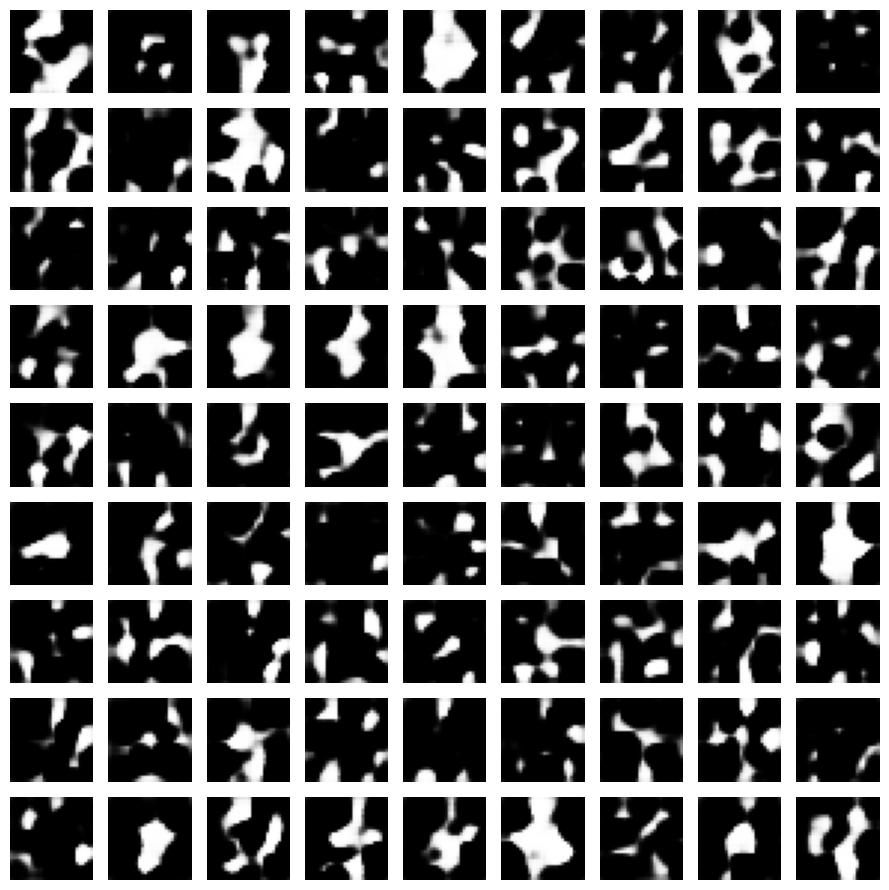

Epoch: 02/30 | Loss G: 2.9998 | Loss D: 0.1140 | Acc G: %0.91 | Acc D: %97.50


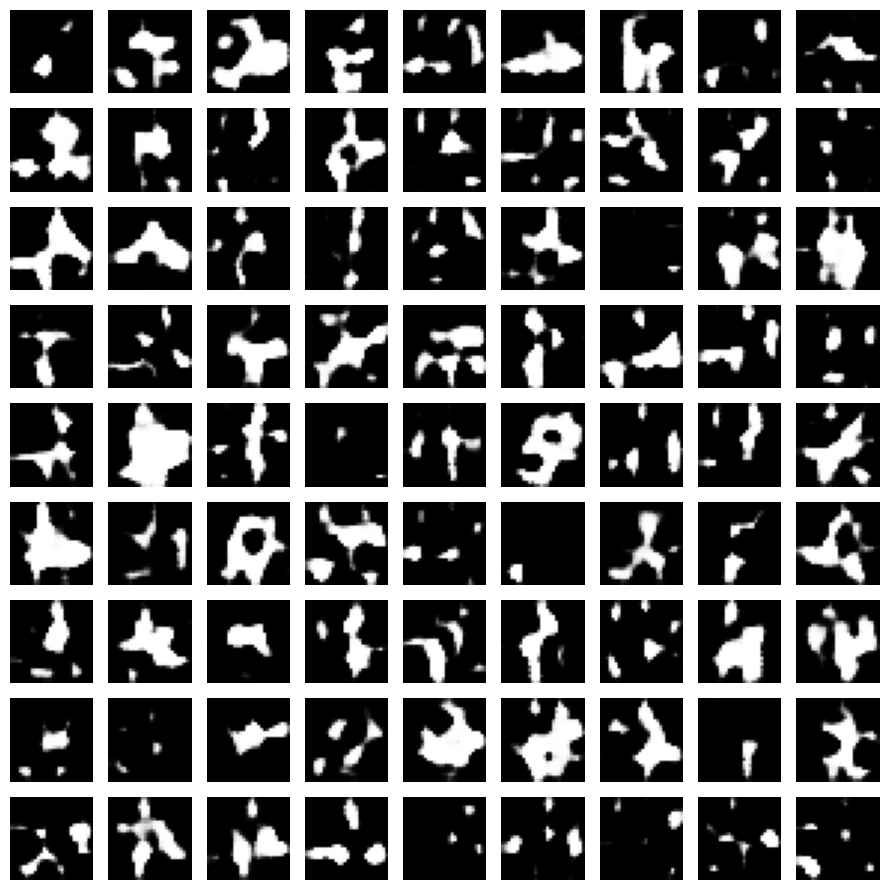

Epoch: 03/30 | Loss G: 3.6683 | Loss D: 0.0802 | Acc G: %0.87 | Acc D: %97.44


KeyboardInterrupt: 

In [12]:
# 30 epoxluq rəqabətli təlim dövrü
EPOCHS = 30

for epoch in range(EPOCHS):
    dLossSum = 0.0
    gLossSum = 0.0
    dAccSum = 0.0
    gAccSum = 0.0
    cnt = 0

    # Dataset üzrə partiyalarla dövr edirik
    for batch in dataset:
        # 1. Diskriminatoru təlim edirik
        dLoss = trainDStep(batch)
        dLossSum += float(dLoss['discriminator_loss'])
        dAccSum += float(dLoss['discriminator_accuracy'])

        # 2. Qeneratoru təlim edirik
        gLoss = trainGStep(batch)
        gLossSum += float(gLoss['generator_loss'])
        gAccSum += float(gLoss['generator_accuracy'])

        cnt += 1

    # Hər epoxun yekun statistikası
    print(f"Epoch: {epoch+1:02d}/{EPOCHS:02d} | Loss G: {gLossSum/cnt:.4f} | Loss D: {dLossSum/cnt:.4f} | Acc G: %{100*gAccSum/cnt:.2f} | Acc D: %{100*dAccSum/cnt:.2f}")

    # Hər 2 epoxdan bir hasil olunan şəkilləri vizuallaşdırırıq
    if (epoch + 1) % 2 == 0 or epoch == 0:
        plotImages(generator)

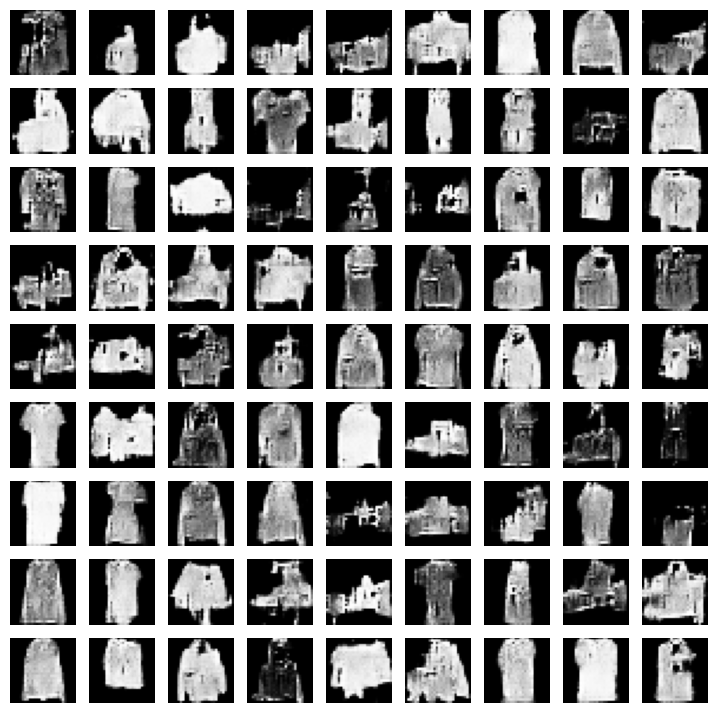

In [ ]:
# Təlim olunmuş Generator ilə yekun 81 süni geyim nümunəsinin hasil edilməsi
# Diqqət edin: Şəkillərin hasil edilməsi millisaniyələr çəkir!
# Klassik kompüter qrafikasında (3D render) bu dəqiqələrlə vaxt aparardı.
# Bu səbəbdən GAN-lar oyun və animasiya sənayesində realistik səhnələrin anlıq yaradılmasında inqilab etdi.

images = generator(np.random.normal(size=(81, NOISE_DIM)), training=False)

plt.figure(figsize=(9, 9))
for i, image in enumerate(images):
    plt.subplot(9, 9, i + 1)
    plt.imshow(np.squeeze(image, -1), cmap="Greys_r")
    plt.axis('off')

plt.suptitle("Təlim Olunmuş GAN Tərəfindən Hasil Edilmiş Yeni Geyimlər", fontsize=14, y=0.98)
plt.tight_layout()
plt.show();

## 🏆 Yekun Xülasə və GAN-ların Ən Böyük Çətinlikləri

### ⚠️ Rejim Çöküşü (Mode Collapse) Problemi Nədir?
Əgər hasil olunan şəkillərə diqqətlə baxsanız, bəzən Generatorun yalnız bir və ya iki geyim növünü (məsələn, yalnız qısaqol köynək və ya çantanı) təkrar-təkrar çəkdiyini görə bilərsiniz. 
* Buna Dərin Öyrənmədə **Rejim Çöküşü (*Mode Collapse*)** deyilir.
* Generator Diskriminatoru aldatmağın ən asan yolunu tapdıqda (məsələn: *"Mən həmişə qara köynək çəksəm, detektiv aldanır"*), risk etmir və digər 9 geyim sinfini çəkməkdən imtina edir.
* **Müasir Həllər:** Wasserstein GAN (WGAN), Spectral Normalization və Conditional GAN (cGAN) bu problemi həll etmək üçün yaradılmışdır.

---

### 📊 VAE vs GAN: Müqayisəli Nəticə

| Meyar | Variational AutoEncoder (VAE) | Generative Adversarial Network (GAN) |
| :--- | :--- | :--- |
| **İş Prinsipi** | Ehtimal paylanması ($\mu, \sigma$) və riyazi bərpa | İki şəbəkənin rəqabətli oyunu (Minimax Game) |
| **Təlim Sabitliyi** | Çox sabit və rahat konvergensiya edir | Çox həssas və şıltaqdır (Divergence riski) |
| **Şəkil Keyfiyyəti** | Bir qədər dumanlı və hamarlaşdırılmış şəkillər | İfrat dərəcədə kəskin və foto-realistik detallar |
| **Əsas Tətbiqi** | Latent fəzanın riyazi nizamı, anomaliya aşkarlanması | Foto-realistik insan üzləri, oyun dizaynı, DeepFake |